<div dir="rtl">

# תרגול: ניתוח תוצאות סימולציה תחת אילוצים


## במחברת זו נשתמש בפונקציה `simulate_single_server_queue_from_times` כדי לענות על שאלות תפעוליות במערכת תור עם שרת יחיד.

### הפונקציה מקבלת מערך זמני בין-הגעות ומערך זמני שירות, ומחזירה ארבעה גדלים מרכזיים:


### 1. `waiting_times` - זמני המתנה בתור, כלומר $W_q$.
### 2. `sojourn_times` - זמני שהייה במערכת, כלומר $W = W_q + S$.
### 3. `queue_length_distribution` - התפלגות זמן-משוקללת של אורך התור, כלומר $L_q$.
### 4. `number_in_system_distribution` - התפלגות זמן-משוקללת של מספר הלקוחות במערכת, כלומר $L$.

### המטרה כאן היא לא רק להריץ סימולציה, אלא להשתמש בתוצאות כדי לקבל החלטות: קצב שירות נדרש, נצילות מותרת, והסתברות לעמידה ביעדי שירות.

</div>


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys

sys.path.append('../../code')
from utils import simulate_single_server_queue_from_times

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True


<div dir="rtl">

## פונקציות עזר

## נרצה להריץ כמה רפליקציות לכל תרחיש, כי תוצאה של סימולציה אחת יכולה להיות רועשת.

## בכל תרחיש נגדיר:

### - קצב הגעה $\lambda$
### - קצב שירות $\mu$
### - נצילות $\rho = \lambda / \mu$

###  כאן נשתמש בזמני בין-הגעות אקספוננציאליים ובזמני שירות אקספוננציאליים. כלומר זהו תור מסוג \(M/M/1\), אבל את המדדים נחשב מסימולציה ולא מנוסחאות אנליטיות.




## The function: simulate_single_server_queue_from_times get inter-arrival and service times
### Return: waiting_times, sojourn_times, queue_length_distribution, number_in_system_distribution 

<div dir="rtl">

## שאלה 1: בחירת קצב שירות תחת אילוץ על אורך התור

### נתונה מערכת תור עם שרת יחיד.
### קצב ההגעה החיצוני הוא:

### $$\lambda = 0.75$$

### נרצה לבחור את קצב השירות $\mu$.
### ככל ש-$\mu$ גדול יותר, השירות מהיר יותר, אבל בדרך כלל גם יקר יותר.
### לכן לא נחפש סתם קצב שירות גדול מאוד, אלא את קצב השירות האיטי ביותר שעדיין עומד בדרישת השירות.

### דרישת השירות היא:

### ההסתברות שאורך התור יהיה גדול מ-5 לא תעלה על 10%.

### כלומר:

### $$P(L_q > 5) \le 0.10$$

### כאשר $L_q$ הוא מספר הלקוחות שממתינים בתור, לא כולל הלקוח שנמצא בשירות.

### שאלת האופטימיזציה:

### למצוא את קצב השירות המינימלי $\mu$ מתוך רשת הערכים שנבדוק, כך שמתקיים:

### $$P(L_q > 5) \le 0.10$$

### את ההסתברות הזאת לא נחשב מנוסחה אנליטית.
### במקום זאת נריץ סימולציה עבור כל ערך מועמד של $\mu$, נקבל את ההתפלגות הזמן-משוקללת של $L_q$, ומתוכה נאמוד את $P(L_q > 5)$.

</div>


In [19]:
arrival_rate = 0.75
queue_threshold = 5
max_probability_queue_too_long = 0.10

service_rate_grid = np.round(np.arange(0.82, 1.61, 0.04), 2)

service_rate_grid

array([0.82, 0.86, 0.9 , 0.94, 0.98, 1.02, 1.06, 1.1 , 1.14, 1.18, 1.22,
       1.26, 1.3 , 1.34, 1.38, 1.42, 1.46, 1.5 , 1.54, 1.58])

In [20]:
float(np.sum(queue_length_distribution[queue_threshold + 1:]))

0.00353366861599619

In [22]:
question_1_results = []
rng = np.random.default_rng(10_000)
Q_1_sim_1 = None

for service_rate in service_rate_grid:
    if service_rate <= arrival_rate:
        continue

    replication_rows = []

    for replication in range(5):
        
        # Generating random inter-arrival and service times 
        inter_arrival_times = rng.exponential(scale=1 / arrival_rate, size=30_000)
        service_times = rng.exponential(scale=1 / service_rate, size=30_000)

        # 
        waiting_times, sojourn_times, queue_length_distribution, number_in_system_distribution = simulate_single_server_queue_from_times(
            inter_arrival_times=inter_arrival_times,
            service_times=service_times,
        )



        p_queue_above_threshold = float(np.sum(queue_length_distribution[queue_threshold + 1:]))

        ## Extracting all important values
        replication_rows.append({
            'mean_waiting_time': float(np.mean(waiting_times)),
            'mean_sojourn_time': float(np.mean(sojourn_times)),
            'p_queue_above_threshold': p_queue_above_threshold,
            'p_queue_at_most_threshold': 1 - p_queue_above_threshold,
            'max_queue_observed': len(queue_length_distribution) - 1,
            'max_number_in_system_observed': len(number_in_system_distribution) - 1,
        })

    ## Entering results in final pandas
    
    result = {}
    for key in replication_rows[0]:
        values = np.array([row[key] for row in replication_rows], dtype=float)
        result[key] = float(np.mean(values))
        result[key + '_std'] = float(np.std(values, ddof=1))

    result['arrival_rate'] = float(arrival_rate)
    result['service_rate'] = float(service_rate)
    result['mean_service_time'] = float(1 / service_rate)
    result['utilization'] = float(arrival_rate / service_rate)
    result['num_customers'] = 30_000
    result['num_replications'] = 5

    question_1_results.append(result)


question_1_df = pd.DataFrame(question_1_results)[[
    'service_rate',
    'mean_service_time',
    'utilization',
    'mean_waiting_time',
    'mean_sojourn_time',
    'p_queue_above_threshold',
    'p_queue_at_most_threshold',
]].round(4)

question_1_df


,service_rate,mean_service_time,utilization,mean_waiting_time,mean_sojourn_time,p_queue_above_threshold,p_queue_at_most_threshold
0,0.82,1.2195,0.9146,12.5546,13.7744,0.5297,0.4703
1,0.86,1.1628,0.8721,7.7110,8.8697,0.3775,0.6225
2,0.90,1.1111,0.8333,5.5984,6.7071,0.2813,0.7187
3,0.94,1.0638,0.7979,4.1713,5.2343,0.2066,0.7934
4,0.98,1.0204,0.7653,3.2189,4.2338,0.1475,0.8525
5,1.02,0.9804,0.7353,2.7523,3.7273,0.1163,0.8837
6,1.06,0.9434,0.7075,2.1642,3.1024,0.0799,0.9201
7,1.10,0.9091,0.6818,1.9229,2.8301,0.0678,0.9322
8,1.14,0.8772,0.6579,1.6765,2.5514,0.0522,0.9478
9,1.18,0.8475,0.6356,1.4693,2.3161,0.0405,0.9595


In [24]:
# Find all service rates that satisfy the queue-length constraint.
feasible_q1 = [
    row for row in question_1_results
    if row['p_queue_above_threshold'] <= max_probability_queue_too_long
]

# The first feasible value is the slowest service rate in the grid that satisfies the constraint.
chosen_q1 = feasible_q1[0]
chosen_q1


{'mean_waiting_time': 2.1641943453753196,
 'mean_waiting_time_std': 0.11763453174476383,
 'mean_sojourn_time': 3.102397726576676,
 'mean_sojourn_time_std': 0.12057272347566297,
 'p_queue_above_threshold': 0.07993102593360782,
 'p_queue_above_threshold_std': 0.011331552943511245,
 'p_queue_at_most_threshold': 0.9200689740663922,
 'p_queue_at_most_threshold_std': 0.011331552943511276,
 'max_queue_observed': 23.8,
 'max_queue_observed_std': 5.11859355682789,
 'max_number_in_system_observed': 24.8,
 'max_number_in_system_observed_std': 5.11859355682789,
 'arrival_rate': 0.75,
 'service_rate': 1.06,
 'mean_service_time': 0.9433962264150942,
 'utilization': 0.7075471698113207,
 'num_customers': 30000,
 'num_replications': 5}

In [25]:




print('Chosen service rate mu:', round(chosen_q1['service_rate'], 4))
print('Mean service time 1/mu:', round(chosen_q1['mean_service_time'], 4))
print('Utilization rho:', round(chosen_q1['utilization'], 4))
print('Estimated P(Lq > 5):', round(chosen_q1['p_queue_above_threshold'], 4))
print('Estimated P(Lq <= 5):', round(chosen_q1['p_queue_at_most_threshold'], 4))


Chosen service rate mu: 1.06
Mean service time 1/mu: 0.9434
Utilization rho: 0.7075
Estimated P(Lq > 5): 0.0799
Estimated P(Lq <= 5): 0.9201


<div dir="rtl">

### נעשה ויזואליזציה של הבעיה

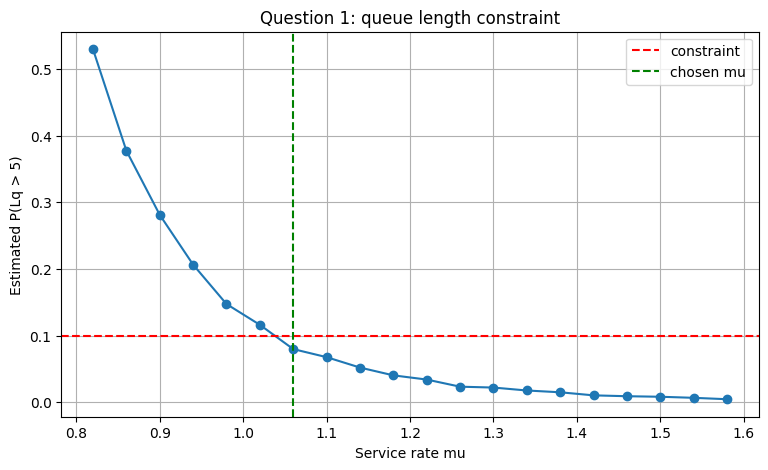

In [26]:
plt.figure()
plt.plot(
    question_1_df['service_rate'],
    question_1_df['p_queue_above_threshold'],
    marker='o',
)
plt.axhline(max_probability_queue_too_long, color='red', linestyle='--', label='constraint')
plt.axvline(chosen_q1['service_rate'], color='green', linestyle='--', label='chosen mu')
plt.xlabel('Service rate mu')
plt.ylabel('Estimated P(Lq > 5)')
plt.title('Question 1: queue length constraint')
plt.legend()
plt.show()


<div dir="rtl">

### פתרון מילולי לשאלה 1

### עברנו על רשת של ערכי $\mu$, מהאיטי למהיר. לכל ערך הרצנו כמה רפליקציות וחישבנו את ההסתברות הזמן-משוקללת שהתור ארוך מ-5.

### הערך הראשון שעומד באילוץ הוא קצב השירות האיטי ביותר ברשת שבדקנו.

### אם רוצים דיוק גבוה יותר, אפשר להקטין את הצעד ברשת סביב הערך שנבחר, למשל לבדוק בקפיצות של `0.01` במקום `0.04`.

### בגלל שאנחנו יודעים שהפתרון נמצא בין 1.04 ל-1.06 אפשר לעשות קפיצות קטנות רק באיזור הזה. 


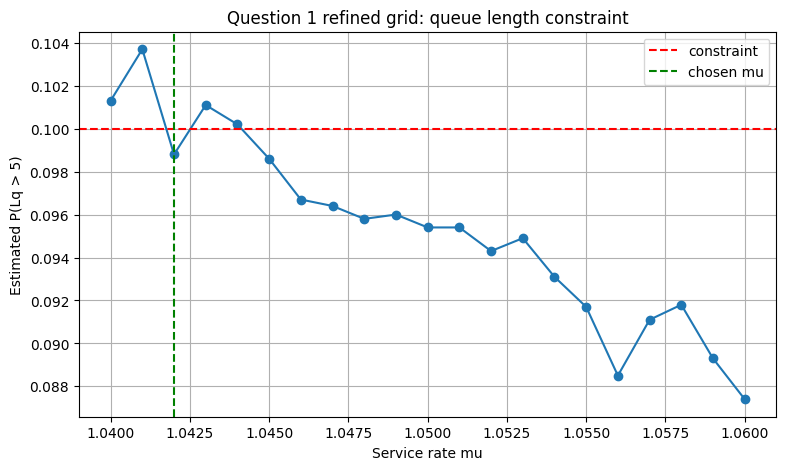

,service_rate,mean_service_time,utilization,p_queue_above_threshold,p_queue_at_most_threshold
0,1.040,0.9615,0.7212,0.1013,0.8987
1,1.041,0.9606,0.7205,0.1037,0.8963
2,1.042,0.9597,0.7198,0.0988,0.9012
3,1.043,0.9588,0.7191,0.1011,0.8989
4,1.044,0.9579,0.7184,0.1002,0.8998
5,1.045,0.9569,0.7177,0.0986,0.9014
6,1.046,0.9560,0.7170,0.0967,0.9033
7,1.047,0.9551,0.7163,0.0964,0.9036
8,1.048,0.9542,0.7156,0.0958,0.9042
9,1.049,0.9533,0.7150,0.0960,0.9040


In [31]:
service_rate_grid = np.round(np.arange(1.04, 1.061, 0.001), 5)

question_1_refined_results = []
rng = np.random.default_rng(10_000)
Q_1_refined_sim_1 = None

for service_rate in service_rate_grid:
    if service_rate <= arrival_rate:
        continue

    replication_rows = []

    for replication in range(3):
        inter_arrival_times = rng.exponential(scale=1 / arrival_rate, size=500_000)
        service_times = rng.exponential(scale=1 / service_rate, size=500_000)

        # Q_1_refined_sim_current = simulate_single_server_queue_from_times(
        #     inter_arrival_times=inter_arrival_times,
        #     service_times=service_times,
        # )

        # if Q_1_refined_sim_1 is None:
        #     Q_1_refined_sim_1 = Q_1_refined_sim_current

        waiting_times, sojourn_times, queue_length_distribution, number_in_system_distribution = simulate_single_server_queue_from_times(
            inter_arrival_times=inter_arrival_times,
            service_times=service_times,
        )

        if len(queue_length_distribution) <= queue_threshold + 1:
            p_queue_above_threshold = 0.0
        else:
            p_queue_above_threshold = float(np.sum(queue_length_distribution[queue_threshold + 1:]))

        replication_rows.append({
            'p_queue_above_threshold': p_queue_above_threshold,
            'p_queue_at_most_threshold': 1 - p_queue_above_threshold,
        })

    result = {}
    for key in replication_rows[0]:
        values = np.array([row[key] for row in replication_rows], dtype=float)
        result[key] = float(np.mean(values))
        result[key + '_std'] = float(np.std(values, ddof=1))

    result['arrival_rate'] = float(arrival_rate)
    result['service_rate'] = float(service_rate)
    result['mean_service_time'] = float(1 / service_rate)
    result['utilization'] = float(arrival_rate / service_rate)
    result['num_customers'] = 80_000
    result['num_replications'] = 3

    question_1_refined_results.append(result)

question_1_refined_df = pd.DataFrame(question_1_refined_results)[[
    'service_rate',
    'mean_service_time',
    'utilization',
    'p_queue_above_threshold',
    'p_queue_at_most_threshold',
]].round(4)

feasible_q1_refined = [
    row for row in question_1_refined_results
    if row['p_queue_above_threshold'] <= max_probability_queue_too_long
]
chosen_q1_refined = feasible_q1_refined[0]

plt.figure()
plt.plot(
    question_1_refined_df['service_rate'],
    question_1_refined_df['p_queue_above_threshold'],
    marker='o',
)
plt.axhline(max_probability_queue_too_long, color='red', linestyle='--', label='constraint')
plt.axvline(chosen_q1_refined['service_rate'], color='green', linestyle='--', label='chosen mu')
plt.xlabel('Service rate mu')
plt.ylabel('Estimated P(Lq > 5)')
plt.title('Question 1 refined grid: queue length constraint')
plt.legend()
plt.show()

question_1_refined_df


<div dir="rtl">

## שאלה 2: זמני שהייה - איזו נצילות מותרת כדי שזמן השהייה יהיה קטן מערך סף?

###    רוצים לוודא שממוצע זמן השהייה הכולל במערכת, כלומר המתנה + שירות, לא יעלה על 3 דקות.

### קצב ההגעה הוא:

## $$ \lambda = 0.60 $$


### השאלה:


### **מהי הנצילות המקסימלית בערך, כך שממוצע זמן השהייה במערכת יהיה קטן או שווה ל-3 דקות?**

###  כלומר נחפש את $\mu$ האיטי ביותר שעבורו:

$$ E[W] \le 3 $$

### ואז נחשב:

## $$ \rho = \frac{\lambda}{\mu} $$

</div>


In [32]:
arrival_rate = 0.60
target_mean_sojourn = 3.0
service_rate_grid = np.round(np.arange(0.65, 1.61, 0.05), 2)

question_2_results = []
rng = np.random.default_rng(20_000)
Q_2_sim_1 = None

for service_rate in service_rate_grid:
    if service_rate <= arrival_rate:
        continue

    replication_rows = []

    for replication in range(5):
        inter_arrival_times = rng.exponential(scale=1 / arrival_rate, size=30_000)
        service_times = rng.exponential(scale=1 / service_rate, size=30_000)



        waiting_times, sojourn_times, queue_length_distribution, number_in_system_distribution = simulate_single_server_queue_from_times(
            inter_arrival_times=inter_arrival_times,
            service_times=service_times,
        )

        replication_rows.append({
            'mean_waiting_time': float(np.mean(waiting_times)),
            'mean_sojourn_time': float(np.mean(sojourn_times)),
            'max_queue_observed': len(queue_length_distribution) - 1,
            'max_number_in_system_observed': len(number_in_system_distribution) - 1,
        })

    result = {}
    for key in replication_rows[0]:
        values = np.array([row[key] for row in replication_rows], dtype=float)
        result[key] = float(np.mean(values))
        result[key + '_std'] = float(np.std(values, ddof=1))

    result['arrival_rate'] = float(arrival_rate)
    result['service_rate'] = float(service_rate)
    result['mean_service_time'] = float(1 / service_rate)
    result['utilization'] = float(arrival_rate / service_rate)
    result['num_customers'] = 30_000
    result['num_replications'] = 5

    question_2_results.append(result)

question_2_df = pd.DataFrame(question_2_results)[[
    'service_rate',
    'mean_service_time',
    'utilization',
    'mean_waiting_time',
    'mean_sojourn_time',
]].round(4)

question_2_df


,service_rate,mean_service_time,utilization,mean_waiting_time,mean_sojourn_time
0,0.65,1.5385,0.9231,18.0392,19.5758
1,0.70,1.4286,0.8571,8.3940,9.8261
2,0.75,1.3333,0.8000,5.2517,6.5868
3,0.80,1.2500,0.7500,3.6965,4.9494
4,0.85,1.1765,0.7059,2.7617,3.9344
5,0.90,1.1111,0.6667,2.2255,3.3335
6,0.95,1.0526,0.6316,1.8394,2.8931
7,1.00,1.0000,0.6000,1.4929,2.4907
8,1.05,0.9524,0.5714,1.2634,2.2161
9,1.10,0.9091,0.5455,1.0926,2.0027


In [33]:
# Checking all possible solutions.
# The first feasible value is the minimum service rate in the grid.
feasible_q2 = [
    row for row in question_2_results
    if row['mean_sojourn_time'] <= target_mean_sojourn
]

chosen_q2 = feasible_q2[0]
chosen_q2


{'mean_waiting_time': 1.839449157487802,
 'mean_waiting_time_std': 0.04694257479217632,
 'mean_sojourn_time': 2.8930773402943872,
 'mean_sojourn_time_std': 0.04936458840123995,
 'max_queue_observed': 19.6,
 'max_queue_observed_std': 3.2093613071762426,
 'max_number_in_system_observed': 20.6,
 'max_number_in_system_observed_std': 3.2093613071762426,
 'arrival_rate': 0.6,
 'service_rate': 0.95,
 'mean_service_time': 1.0526315789473684,
 'utilization': 0.631578947368421,
 'num_customers': 30000,
 'num_replications': 5}

In [34]:


print('Chosen service rate mu:', round(chosen_q2['service_rate'], 4))
print('Mean service time 1/mu:', round(chosen_q2['mean_service_time'], 4))
print('Maximum utilization on this grid:', round(chosen_q2['utilization'], 4))
print('Estimated mean sojourn time:', round(chosen_q2['mean_sojourn_time'], 4))
print('Estimated mean waiting time:', round(chosen_q2['mean_waiting_time'], 4))


Chosen service rate mu: 0.95
Mean service time 1/mu: 1.0526
Maximum utilization on this grid: 0.6316
Estimated mean sojourn time: 2.8931
Estimated mean waiting time: 1.8394


In [35]:
question_2_df[['utilization', 'mean_sojourn_time']]


,utilization,mean_sojourn_time
0,0.9231,19.5758
1,0.8571,9.8261
2,0.8000,6.5868
3,0.7500,4.9494
4,0.7059,3.9344
5,0.6667,3.3335
6,0.6316,2.8931
7,0.6000,2.4907
8,0.5714,2.2161
9,0.5455,2.0027


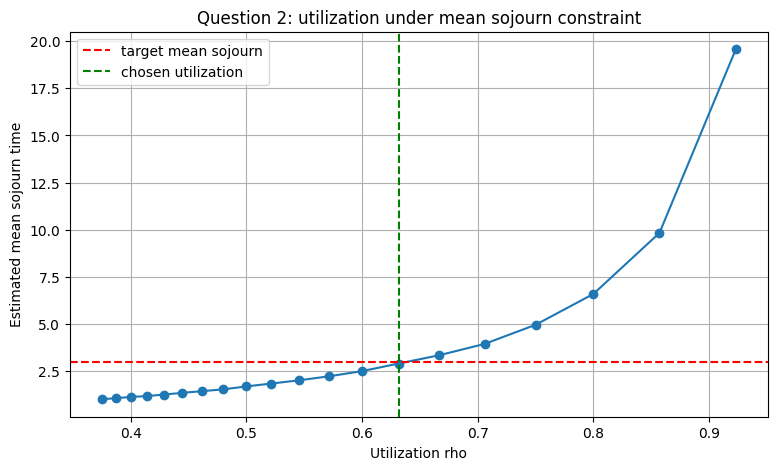

In [36]:
plt.figure()
plt.plot(
    question_2_df['utilization'],
    question_2_df['mean_sojourn_time'],
    marker='o',
)
plt.axhline(target_mean_sojourn, color='red', linestyle='--', label='target mean sojourn')
plt.axvline(chosen_q2['utilization'], color='green', linestyle='--', label='chosen utilization')
plt.xlabel('Utilization rho')
plt.ylabel('Estimated mean sojourn time')
plt.title('Question 2: utilization under mean sojourn constraint')
plt.legend()
plt.show()


<div dir="rtl">

### פתרון מילולי לשאלה 2


### כאן המדד המרכזי הוא זמן השהייה במערכת:

### $$ W = W_q + S $$

#### עבור כל קצב שירות חישבנו ממוצע של `sojourn_times`. ככל שהשירות מהיר יותר, הנצילות $\rho$ יורדת וזמן השהייה קטן.

#### הבחירה התפעולית היא קצב השירות האיטי ביותר שעדיין משאיר את ממוצע זמן השהייה מתחת לסף. מכאן מקבלים את הנצילות המקסימלית שהמערכת יכולה להרשות לעצמה בתנאים האלו.

</div>


<div dir="rtl">

## שאלה 3: מרפאת ערב - עמידה ביעד המתנה

## במרפאת ערב מגיעים מטופלים בקצב ממוצע:

### $$\lambda = 0.80 $$

### ההנהלה רוצה שלכל היותר 5% מהמטופלים יחכו יותר מ-3 דקות בתור.

### השאלה:

###  **מהו קצב השירות האיטי ביותר $\mu$ כך שיתקיים:**

### $$ P(W_q > 3) \le 0.05 $$


###  כאן אנחנו משתמשים ישירות במערך `waiting_times` שהסימולציה מחזירה.

</div>


In [37]:
# Service rate starts at 0.85 because the system is unstable when mu <= lambda = 0.80.
arrival_rate = 0.80
wait_threshold = 3.0
max_probability_wait_too_long = 0.05
service_rate_grid = np.round(np.arange(0.85, 1.81, 0.05), 2)

service_rate_grid


array([0.85, 0.9 , 0.95, 1.  , 1.05, 1.1 , 1.15, 1.2 , 1.25, 1.3 , 1.35,
       1.4 , 1.45, 1.5 , 1.55, 1.6 , 1.65, 1.7 , 1.75, 1.8 ])

In [38]:
question_3_results = []
rng = np.random.default_rng(30_000)
Q_3_sim_1 = None

for service_rate in service_rate_grid:
    if service_rate <= arrival_rate:
        continue

    replication_rows = []

    for replication in range(5):
        inter_arrival_times = rng.exponential(scale=1 / arrival_rate, size=30_000)
        service_times = rng.exponential(scale=1 / service_rate, size=30_000)



        waiting_times, sojourn_times, queue_length_distribution, number_in_system_distribution = simulate_single_server_queue_from_times(
            inter_arrival_times=inter_arrival_times,
            service_times=service_times,
        )

        replication_rows.append({
            'mean_waiting_time': float(np.mean(waiting_times)),
            'mean_sojourn_time': float(np.mean(sojourn_times)),
            'p_waiting_above_threshold': float(np.mean(waiting_times > wait_threshold)),
            'max_queue_observed': len(queue_length_distribution) - 1,
            'max_number_in_system_observed': len(number_in_system_distribution) - 1,
        })

    result = {}
    for key in replication_rows[0]:
        values = np.array([row[key] for row in replication_rows], dtype=float)
        result[key] = float(np.mean(values))
        result[key + '_std'] = float(np.std(values, ddof=1))

    result['arrival_rate'] = float(arrival_rate)
    result['service_rate'] = float(service_rate)
    result['mean_service_time'] = float(1 / service_rate)
    result['utilization'] = float(arrival_rate / service_rate)
    result['num_customers'] = 30_000
    result['num_replications'] = 5

    question_3_results.append(result)

question_3_df = pd.DataFrame(question_3_results)[[
    'service_rate',
    'mean_service_time',
    'utilization',
    'mean_waiting_time',
    'mean_sojourn_time',
    'p_waiting_above_threshold',
]].round(4)

question_3_df


,service_rate,mean_service_time,utilization,mean_waiting_time,mean_sojourn_time,p_waiting_above_threshold
0,0.85,1.1765,0.9412,20.4756,21.6523,0.8182
1,0.90,1.1111,0.8889,9.6351,10.7522,0.6805
2,0.95,1.0526,0.8421,5.6600,6.7130,0.5384
3,1.00,1.0000,0.8000,3.9964,5.0006,0.4431
4,1.05,0.9524,0.7619,3.0520,4.0025,0.3612
5,1.10,0.9091,0.7273,2.4401,3.3489,0.2958
6,1.15,0.8696,0.6957,1.9551,2.8251,0.2420
7,1.20,0.8333,0.6667,1.6766,2.5082,0.2041
8,1.25,0.8000,0.6400,1.4324,2.2335,0.1681
9,1.30,0.7692,0.6154,1.2519,2.0217,0.1399


In [39]:
feasible_q3 = [
    row for row in question_3_results
    if row['p_waiting_above_threshold'] <= max_probability_wait_too_long
]

chosen_q3 = feasible_q3[0]

print('Chosen service rate mu:', round(chosen_q3['service_rate'], 4))
print('Mean service time 1/mu:', round(chosen_q3['mean_service_time'], 4))
print('Utilization rho:', round(chosen_q3['utilization'], 4))
print('Estimated P(Wq > 3):', round(chosen_q3['p_waiting_above_threshold'], 4))
print('Estimated mean waiting time:', round(chosen_q3['mean_waiting_time'], 4))


Chosen service rate mu: 1.6
Mean service time 1/mu: 0.625
Utilization rho: 0.5
Estimated P(Wq > 3): 0.0438
Estimated mean waiting time: 0.6198


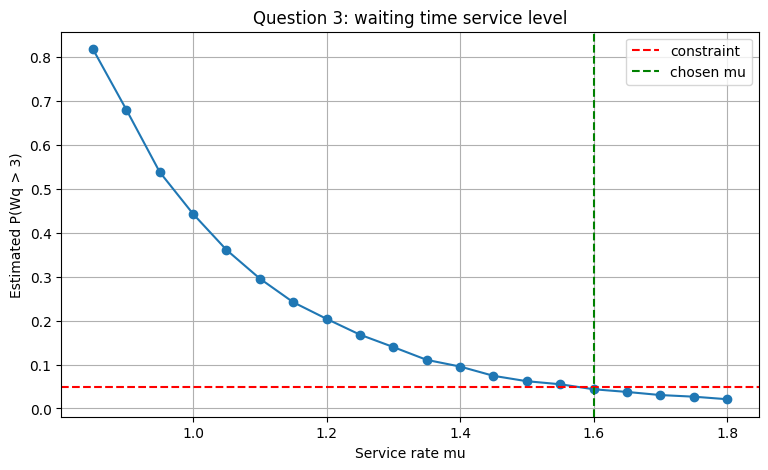

In [40]:
plt.figure()
plt.plot(
    question_3_df['service_rate'],
    question_3_df['p_waiting_above_threshold'],
    marker='o',
)
plt.axhline(max_probability_wait_too_long, color='red', linestyle='--', label='constraint')
plt.axvline(chosen_q3['service_rate'], color='green', linestyle='--', label='chosen mu')
plt.xlabel('Service rate mu')
plt.ylabel('Estimated P(Wq > 3)')
plt.title('Question 3: waiting time service level')
plt.legend()
plt.show()


<div dir="rtl">

### פתרון מילולי לשאלה 3

### בשאלה זו האילוץ הוא לא על ממוצע אלא על זנב ההתפלגות של זמן ההמתנה.

 ### לכן לא מספיק לבדוק ש־`waiting_times.mean()` קטן. אנחנו מחשבים ישירות:

### np.mean(waiting_times > wait_threshold)

### זהו אומד להסתברות שמטופל יחכה יותר מהסף שהוגדר.

</div>


<div dir="rtl">

## סיכום

### בשלוש השאלות השתמשנו באותה פונקציית סימולציה, אבל בכל פעם שאלנו שאלה תפעולית אחרת:

### 1. אילוץ על התפלגות אורך התור: \(P(L_q > n)\).
### 2. אילוץ על ממוצע זמן שהייה: \(E[W]\).
### 3. אילוץ על זנב התפלגות זמן ההמתנה: \(P(W_q > t)\).

### זה בדיוק הכוח של סימולציה: אפשר לתרגם שאלה ניהולית או תפעולית למדד הסתברותי, להריץ תרחישים, ולבחור את הפרמטר הכי זול או הכי איטי שעדיין עומד באילוץ.

</div>
